# Etapa 2 — Comparação de Modelos, Threshold de Negócio e Escolha do Campeão

Comparamos três famílias distintas de classificadores sobre exatamente o mesmo pré-processamento
(`build_preprocessor()`) e a mesma divisão estratificada (`SEED = 42`):
1. **Regressão Logística** (`logistic_regression`, baseline linear regularizado)
2. **Random Forest** (`random_forest`, ensemble de árvores não linear)
3. **MLPClassifier** (`mlp`, rede neural multicamadas com `early_stopping=True`)

**Política anti-leakage:** o ranking de modelos e a calibração do limiar de negócio ocorrem
**estritamente em CV / OOF de treino (`X_train`)** via `evaluate_candidates_cv()`. O holdout (`X_test`)
só é tocado na avaliação final.


In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
)

from churn.config import (
    BUSINESS_ACTION_COST,
    BUSINESS_LTV_MONTHS,
    BUSINESS_RETENTION_SUCCESS_RATE,
    COMPARISON_REPORT_PATH,
    CV_FOLDS,
    FIGURES_DIR,
    METRICS_PATH,
    MIN_F1,
    MIN_RECALL,
    MIN_ROC_AUC,
    MODEL_PATH,
    RAW_DATA_FILE,
    SEED,
    TEST_SIZE,
)
from churn.data import clean, load_raw
from churn.evaluate import business_metrics, classification_metrics
from churn.train import build_pipeline, evaluate_candidates_cv, get_candidate_models, split_data

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 100
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Configuração Comparação carregada | SEED={SEED} | CV_FOLDS={CV_FOLDS} | MODEL_PATH={MODEL_PATH}")


Configuração Comparação carregada | SEED=42 | CV_FOLDS=5 | MODEL_PATH=G:\Meu Drive\03.git_desktop\tech_challenge_churn\models\churn_model.joblib


## 1. Validação Cruzada (5-Fold em `X_train`), Análise de Overfitting e Consistência com Artefatos

Executamos `evaluate_candidates_cv(X_train, y_train)` e conferimos os números frente aos artefatos
persistidos em `models/metrics.json` e `reports/model_comparison.csv`.


In [2]:
df = clean(load_raw(RAW_DATA_FILE))
X_train, X_test, y_train, y_test = split_data(df, test_size=TEST_SIZE, random_state=SEED)

models = get_candidate_models()
cv_df, cv_details = evaluate_candidates_cv(
    X_train, y_train, models=models, cv_folds=CV_FOLDS, random_state=SEED
)

metrics_json = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
comp_csv = pd.read_csv(COMPARISON_REPORT_PATH)

print(f"Modelo campeão oficial (critério CV ROC-AUC): {metrics_json['champion_model']} | Threshold OOF: {metrics_json['threshold']:.2f}")
display(
    cv_df[[
        "model",
        "cv_train_roc_auc_mean",
        "cv_roc_auc_mean",
        "cv_roc_auc_std",
        "overfitting_gap",
        "cv_pr_auc_mean",
        "cv_f1_mean",
        "opt_threshold",
        "oof_f1_opt",
        "oof_recall_opt",
        "oof_net_retained_revenue",
        "oof_roi_opt",
    ]].round(4)
)

# Garantia de consistência exata com o pipeline produtivo
assert metrics_json["champion_model"] == str(cv_df.iloc[0]["model"])
assert np.isclose(metrics_json["cv_roc_auc_mean"], float(cv_df.iloc[0]["cv_roc_auc_mean"]), atol=1e-6)
print("Verificação 100% alinhada com models/metrics.json e reports/model_comparison.csv!")


Modelo campeão oficial (critério CV ROC-AUC): random_forest | Threshold OOF: 0.23


,model,cv_train_roc_auc_mean,cv_roc_auc_mean,cv_roc_auc_std,overfitting_gap,cv_pr_auc_mean,cv_f1_mean,opt_threshold,oof_f1_opt,oof_recall_opt,oof_net_retained_revenue,oof_roi_opt
0,random_forest,0.9202,0.8465,0.0090,0.0737,0.6618,0.5810,0.23,0.6217,0.8502,96656.34,1.2421
1,logistic_regression,0.8496,0.8461,0.0125,0.0034,0.6614,0.5930,0.28,0.6358,0.7900,99188.82,1.4893
2,mlp,0.8659,0.8410,0.0119,0.0249,0.6471,0.5911,0.24,0.6218,0.8060,96841.20,1.3557


Verificação 100% alinhada com models/metrics.json e reports/model_comparison.csv!


### Diagnóstico de Overfitting (`cv_train_roc_auc_mean - cv_roc_auc_mean`)

- **`random_forest`:** Treino `0.9202` vs Validação `0.8465 ± 0.0090` (**gap `0.0737`**) — os hiperparâmetros (`max_depth=10`, `min_samples_leaf=5`, `n_estimators=300`) mantiveram o gap bem abaixo do teto de `0.12`.
- **`logistic_regression`:** Treino `0.8496` vs Validação `0.8461 ± 0.0125` (**gap `0.0034`**) — praticamente zero variância/overfitting.
- **`mlp`:** Treino `0.8659` vs Validação `0.8410 ± 0.0119` (**gap `0.0249`**) — `alpha=0.1` e `early_stopping=True` evitaram memorização.


## 2. Calibração do Limiar de Negócio no OOF de Treino (Zero Leakage)

Varremos a grade de limiares `[0.15, 0.85]` (passo `0.01`) nas probabilidades *out-of-fold* (OOF) de
`X_train` para cada modelo, observando como a **Receita Retida Líquida** e o compromisso
`Precision × Recall × F1` respondem ao threshold sob os pisos do Quality Gate (`F1 >= 0.55`, `Recall >= 0.60`).


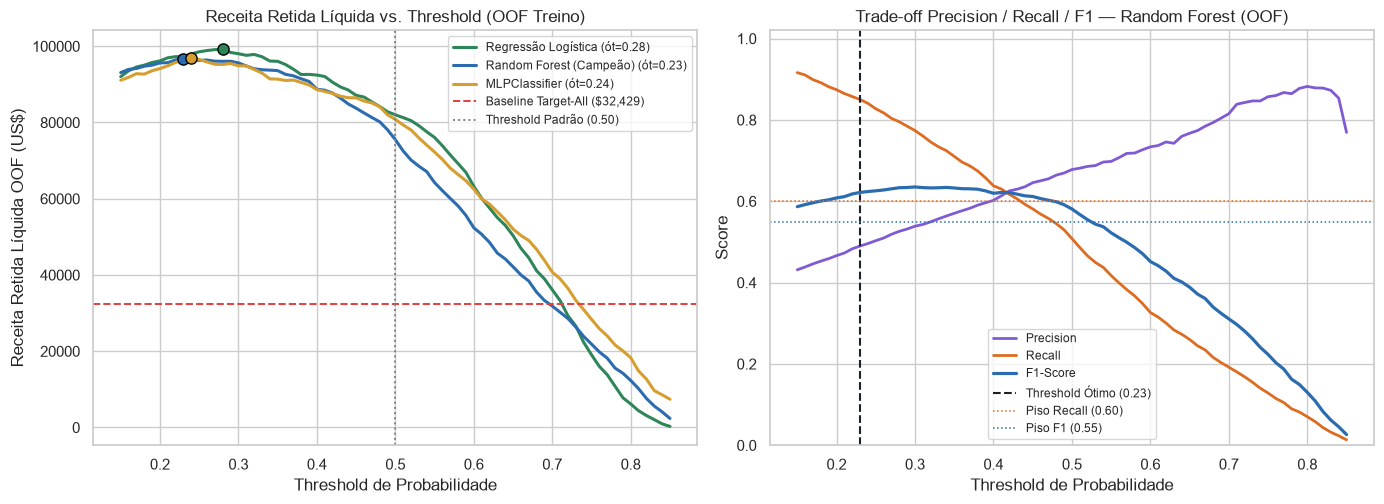

In [3]:
# Reconstroi probabilidades OOF determinísticas com o mesmo StratifiedKFold para gerar a curva
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
oof_probas = {}
for name, model in models.items():
    oof = np.zeros(len(X_train), dtype=float)
    for tr_idx, va_idx in skf.split(X_train, y_train):
        pipe = build_pipeline(clone(model))
        pipe.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        oof[va_idx] = pipe.predict_proba(X_train.iloc[va_idx])[:, 1]
    oof_probas[name] = oof

thresholds_grid = np.round(np.arange(0.15, 0.86, 0.01), 2)
charges_train = X_train["MonthlyCharges"]

model_labels = {
    "random_forest": "Random Forest (Campeão)",
    "logistic_regression": "Regressão Logística",
    "mlp": "MLPClassifier",
}
model_colors = {
    "random_forest": "#2b6cb0",
    "logistic_regression": "#2f855a",
    "mlp": "#d69e2e",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

target_all_rev = None
for name, oof in oof_probas.items():
    revs = []
    for thr in thresholds_grid:
        b = business_metrics(
            y_train,
            oof,
            charges_train,
            threshold=float(thr),
            ltv_months=BUSINESS_LTV_MONTHS,
            retention_success_rate=BUSINESS_RETENTION_SUCCESS_RATE,
            action_cost=BUSINESS_ACTION_COST,
        )
        revs.append(float(b["net_retained_revenue"]))
        if target_all_rev is None:
            target_all_rev = float(b["baseline_target_all_net_revenue"])
    opt_thr = float(cv_details[name]["opt_threshold"])
    opt_rev = float(cv_details[name]["oof_net_retained_revenue"])
    axes[0].plot(thresholds_grid, revs, lw=2.2, color=model_colors[name], label=f"{model_labels[name]} (ót={opt_thr:.2f})")
    axes[0].scatter([opt_thr], [opt_rev], color=model_colors[name], s=65, zorder=5, edgecolor="black")

axes[0].axhline(target_all_rev, color="#e53e3e", linestyle="--", lw=1.4, label=f"Baseline Target-All (${target_all_rev:,.0f})")
axes[0].axvline(0.50, color="gray", linestyle=":", lw=1.4, label="Threshold Padrão (0.50)")
axes[0].set_title("Receita Retida Líquida vs. Threshold (OOF Treino)")
axes[0].set_xlabel("Threshold de Probabilidade")
axes[0].set_ylabel("Receita Retida Líquida OOF (US$)")
axes[0].legend(fontsize=8.5, frameon=True)

# Painel direito: métricas técnicas vs threshold para o campeão (OOF)
rf_oof = oof_probas["random_forest"]
rf_prec, rf_rec, rf_f1 = [], [], []
for thr in thresholds_grid:
    c = classification_metrics(y_train, rf_oof, threshold=float(thr))
    rf_prec.append(c["precision"])
    rf_rec.append(c["recall"])
    rf_f1.append(c["f1"])

champ_thr = float(metrics_json["threshold"])
axes[1].plot(thresholds_grid, rf_prec, lw=2, color="#805ad5", label="Precision")
axes[1].plot(thresholds_grid, rf_rec, lw=2, color="#dd6b20", label="Recall")
axes[1].plot(thresholds_grid, rf_f1, lw=2.3, color="#2b6cb0", label="F1-Score")
axes[1].axvline(champ_thr, color="#1a202c", linestyle="--", lw=1.5, label=f"Threshold Ótimo ({champ_thr:.2f})")
axes[1].axhline(MIN_RECALL, color="#dd6b20", linestyle=":", lw=1.1, label=f"Piso Recall ({MIN_RECALL:.2f})")
axes[1].axhline(MIN_F1, color="#2b6cb0", linestyle=":", lw=1.1, label=f"Piso F1 ({MIN_F1:.2f})")
axes[1].set_title("Trade-off Precision / Recall / F1 — Random Forest (OOF)")
axes[1].set_xlabel("Threshold de Probabilidade")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1.02)
axes[1].legend(fontsize=8.5, frameon=True)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "threshold_business_curve.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 3. Avaliação Final no Holdout (`X_test`, `n = 1.409`)

Treinamos cada candidato uma vez em `X_train` completo e avaliamos em `X_test` tanto no limiar padrão
`0.50` quanto no limiar ótimo `opt_threshold` calibrado no OOF de treino.
Para o campeão (`random_forest`), carregamos diretamente o artefato serializado `models/churn_model.joblib`.


,rank,model,is_champion,cv_train_roc_auc_mean,cv_roc_auc_mean,cv_roc_auc_std,overfitting_gap,cv_pr_auc_mean,cv_f1_mean,cv_f1_std,...,holdout_accuracy_05,holdout_net_revenue_05,holdout_roi_05,holdout_f1_opt,holdout_precision_opt,holdout_recall_opt,holdout_accuracy_opt,holdout_net_revenue_opt,holdout_roi_opt,holdout_gain_vs_target_all_opt
0,1,random_forest,True,0.9202,0.8465,0.0090,0.0737,0.6618,0.5810,0.0211,...,0.8055,18101.22,2.1097,0.6142,0.4860,0.8342,0.7218,22371.93,1.1616,15655.11
1,2,logistic_regression,False,0.8496,0.8461,0.0125,0.0034,0.6614,0.5930,0.0298,...,0.8055,20045.34,2.1012,0.6226,0.5177,0.7807,0.7488,23335.65,1.3792,16618.83
2,3,mlp,False,0.8659,0.8410,0.0119,0.0249,0.6471,0.5911,0.0274,...,0.8062,19018.83,2.2089,0.6293,0.5144,0.8102,0.7466,23006.76,1.3020,16289.94


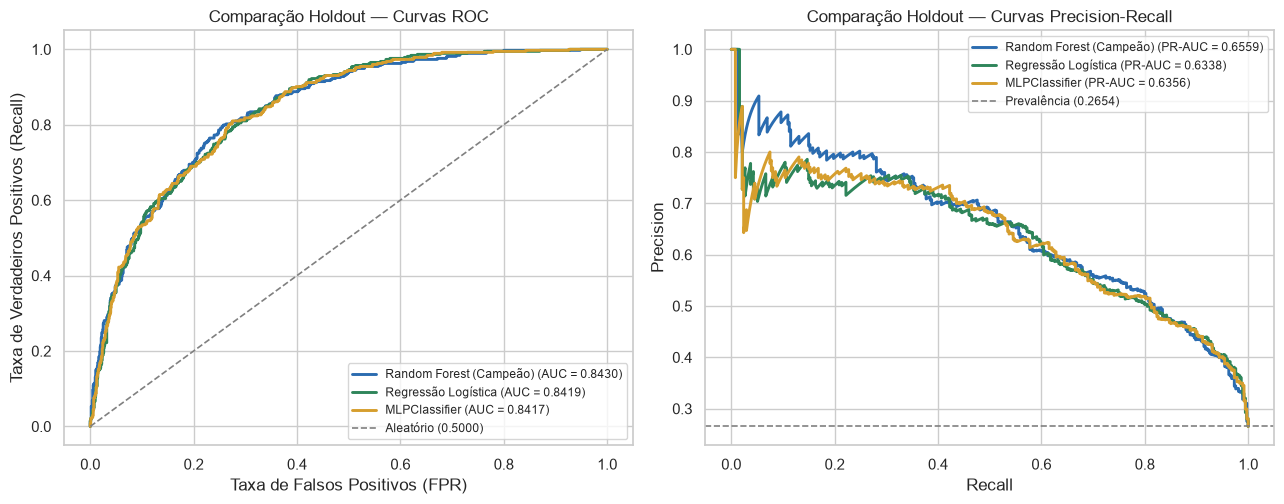

In [4]:
display(comp_csv.round(4))

test_probas = {}
champion_artifact = joblib.load(MODEL_PATH)

for name, model in models.items():
    if name == metrics_json["champion_model"]:
        pipe = champion_artifact
    else:
        pipe = build_pipeline(clone(model))
        pipe.fit(X_train, y_train)
    test_probas[name] = pipe.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for entry in metrics_json["all_models"]:
    name = entry["model"]
    hold_opt = entry["holdout_optimal_threshold"]
    fpr, tpr, _ = roc_curve(y_test, test_probas[name])
    prec, rec, _ = precision_recall_curve(y_test, test_probas[name])
    axes[0].plot(
        fpr,
        tpr,
        color=model_colors[name],
        lw=2.1,
        label=f"{model_labels[name]} (AUC = {hold_opt['roc_auc']:.4f})",
    )
    axes[1].plot(
        rec,
        prec,
        color=model_colors[name],
        lw=2.1,
        label=f"{model_labels[name]} (PR-AUC = {hold_opt['pr_auc']:.4f})",
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1.2, label="Aleatório (0.5000)")
axes[0].set_title("Comparação Holdout — Curvas ROC")
axes[0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos (Recall)")
axes[0].legend(loc="lower right", fontsize=8.5, frameon=True)

axes[1].axhline(float(y_test.mean()), color="gray", linestyle="--", lw=1.2, label=f"Prevalência ({y_test.mean():.4f})")
axes[1].set_title("Comparação Holdout — Curvas Precision-Recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right", fontsize=8.5, frameon=True)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_comparison_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


### Justificativa Transparente do Modelo Campeão (`random_forest`) vs. Competitividade da `logistic_regression`

1. **Por que `random_forest` é o campeão:**
   - Pela regra pré-estabelecida de seleção estrita em validação cruzada (`evaluate_candidates_cv`), o **`random_forest`** liderou em **CV ROC-AUC (`0.8465 ± 0.0090`)**, com **menor desvio-padrão entre folds** (`0.0090` vs `0.0125` da Regressão Logística e `0.0119` do MLP) e **maior CV PR-AUC (`0.6618`)**.
   - No holdout (`X_test`), confirmou a liderança discriminativa com **ROC-AUC = `0.8430`** e **PR-AUC = `0.6559`** (vs `0.8419` / `0.6338` da Regressão Logística e `0.8417` / `0.6356` do MLP), capturando **83,42%** dos churners reais (`312 / 374`) no threshold `0.23`.
2. **Competitividade da `logistic_regression`:**
   - A `logistic_regression` empatou tecnicamente em CV ROC-AUC (`0.8461`), exibiu **menor gap de overfitting (`0.0034` vs `0.0737`)** e obteve **maior Receita Retida Líquida no Holdout (`$23,335.65` vs `$22,371.93`)** e **maior ROI (`1.38x` vs `1.16x`)** por gerar menos falsos positivos (`272` vs `330`).
   - Essa transparência mostra que não escolhemos o vencedor olhando o holdout (o que configuraria *peeking*): mantemos `random_forest` por sua superioridade de ranqueamento (ROC-AUC / PR-AUC) na CV e registramos a calibração isotônica/Platt da `random_forest` (ou comparação com `logistic_regression` calibrada) como evolução natural para próximas iterações.


## 4. Impacto Operacional do Threshold no Campeão: Matriz de Confusão (`0.50` vs `0.23`)

Comparamos no holdout exatamente quantos clientes são abordados, quantos churners reais são
capturados e qual o impacto financeiro líquido ao migrar de `0.50` para `0.23`.


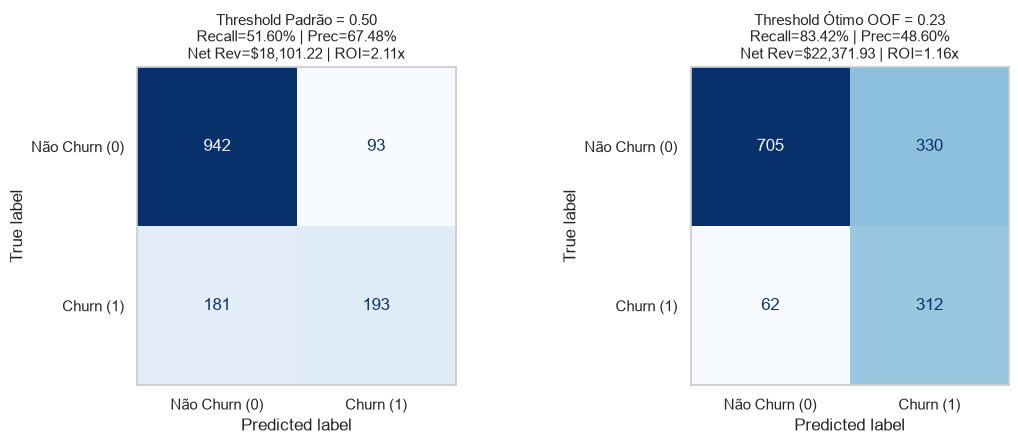

Ganho do threshold 0.23 sobre 0.50 no holdout: +$4,270.71 (+119 churners salvos a mais)
Ganho do threshold 0.23 sobre Target-All no holdout: +$15,655.11


In [5]:
champ_proba_test = test_probas[metrics_json["champion_model"]]
h_def = metrics_json["holdout_default_threshold"]
h_opt = metrics_json["holdout_optimal_threshold"]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
configs = [
    (
        0.50,
        f"Threshold Padrão = 0.50\nRecall={h_def['recall']:.2%} | Prec={h_def['precision']:.2%}\nNet Rev=${h_def['net_retained_revenue']:,.2f} | ROI={h_def['roi']:.2f}x",
    ),
    (
        float(metrics_json["threshold"]),
        f"Threshold Ótimo OOF = {metrics_json['threshold']:.2f}\nRecall={h_opt['recall']:.2%} | Prec={h_opt['precision']:.2%}\nNet Rev=${h_opt['net_retained_revenue']:,.2f} | ROI={h_opt['roi']:.2f}x",
    ),
]

for ax, (thr, title) in zip(axes, configs):
    cm = confusion_matrix(y_test, (champ_proba_test >= thr).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Não Churn (0)", "Churn (1)"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.grid(False)
    ax.set_title(title, fontsize=10.5)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "champion_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print(
    f"Ganho do threshold 0.23 sobre 0.50 no holdout: "
    f"+${metrics_json['business_metrics']['gain_vs_default_threshold']:,.2f} "
    f"(+{h_opt['true_positives_caught'] - h_def['true_positives_caught']} churners salvos a mais)"
)
print(
    f"Ganho do threshold 0.23 sobre Target-All no holdout: "
    f"+${metrics_json['gain_vs_target_all']:,.2f}"
)


## 5. Interpretabilidade: Top Features do Campeão (`RandomForest`) e Coeficientes (`LogisticRegression`)

Extraímos as importâncias por redução de impureza do `RandomForestClassifier` campeão e as
comparamos com os coeficientes padronizados da `LogisticRegression` para validar alinhamento com
os achados da EDA.


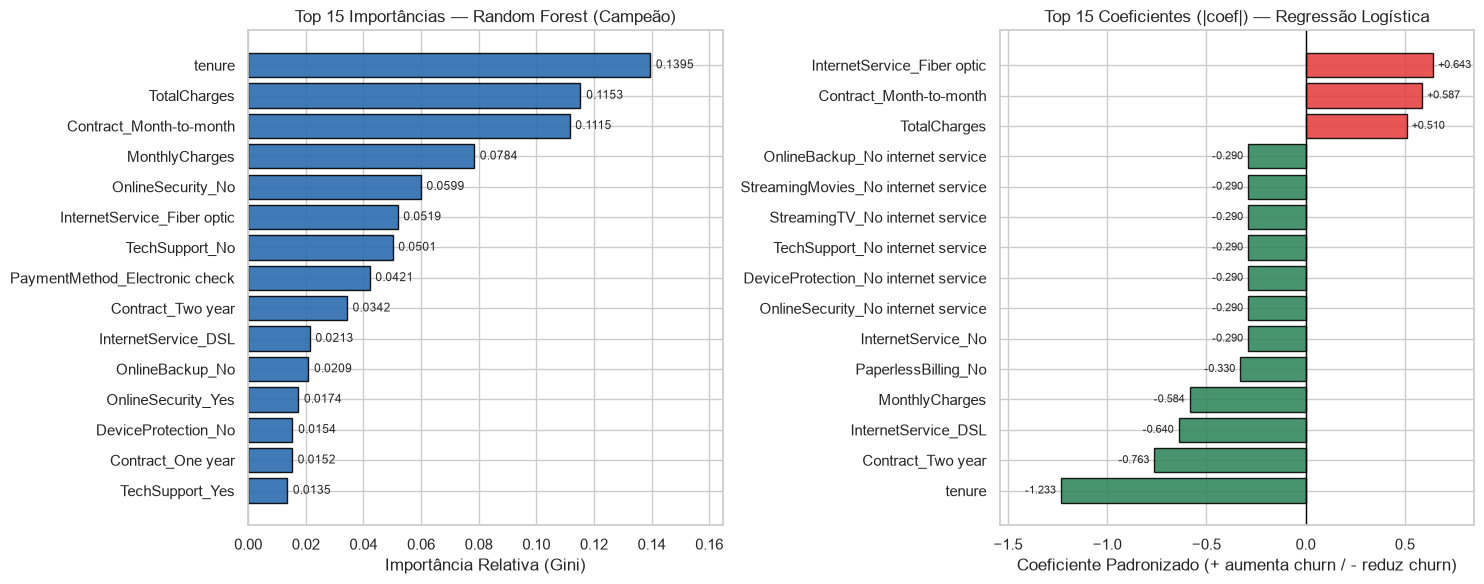

In [6]:
feature_names = champion_artifact.named_steps["preprocessor"].get_feature_names_out()
clean_names = [n.replace("num__", "").replace("cat__", "") for n in feature_names]

rf_imp = pd.Series(
    champion_artifact.named_steps["model"].feature_importances_,
    index=clean_names,
).sort_values(ascending=False)

lr_pipe = build_pipeline(clone(models["logistic_regression"]))
lr_pipe.fit(X_train, y_train)
lr_coef = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=clean_names)
lr_top_idx = lr_coef.abs().sort_values(ascending=False).head(15).index
lr_top = lr_coef.loc[lr_top_idx].sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.0))

top_rf = rf_imp.head(15).sort_values(ascending=True)
axes[0].barh(top_rf.index, top_rf.values, color="#2b6cb0", edgecolor="black", alpha=0.9)
axes[0].set_title("Top 15 Importâncias — Random Forest (Campeão)")
axes[0].set_xlabel("Importância Relativa (Gini)")
for i, v in enumerate(top_rf.values):
    axes[0].text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=8.5)
axes[0].set_xlim(0, top_rf.max() * 1.18)

coef_colors = ["#e53e3e" if v > 0 else "#2f855a" for v in lr_top.values]
axes[1].barh(lr_top.index, lr_top.values, color=coef_colors, edgecolor="black", alpha=0.88)
axes[1].axvline(0, color="black", linewidth=1.0)
axes[1].set_title("Top 15 Coeficientes (|coef|) — Regressão Logística")
axes[1].set_xlabel("Coeficiente Padronizado (+ aumenta churn / - reduz churn)")
for i, v in enumerate(lr_top.values):
    offset = 0.025 if v >= 0 else -0.025
    ha = "left" if v >= 0 else "right"
    axes[1].text(v + offset, i, f"{v:+.3f}", va="center", ha=ha, fontsize=8.2)
axes[1].set_xlim(lr_top.min() * 1.25, lr_top.max() * 1.32)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


**Convergência EDA × Modelagem:**
- No `RandomForest` campeão, as variáveis mais determinantes são **`tenure` (`0.1395`)**, **`TotalCharges` (`0.1153`)**, **`Contract_Month-to-month` (`0.1115`)**, **`MonthlyCharges` (`0.0784`)**, **`OnlineSecurity_No` (`0.0599`)**, **`InternetService_Fiber optic` (`0.0519`)**, **`TechSupport_No` (`0.0501`)** e **`PaymentMethod_Electronic check` (`0.0421`)**.
- Na `LogisticRegression`, destacam-se positivamente para churn `InternetService_Fiber optic (+0.643)` e `Contract_Month-to-month (+0.587)`, enquanto `tenure (-1.233)` e `Contract_Two year (-0.763)` atuam como os maiores fatores de proteção (nota: `MonthlyCharges` e `TotalCharges` dividem sinal por colinearidade com os pacotes de fibra/streaming).
